In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("Không tìm thấy thư mục gốc của project")


PROJECT_ROOT = find_project_root()

In [ ]:
region_id = "29_2" 

parquet_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / region_id
    / "cell_features.parquet"
)

if not parquet_path.exists():
    raise FileNotFoundError(f"Không tìm thấy: {parquet_path}")

features = gpd.read_parquet(parquet_path)
features = features.set_geometry("geometry")

print(f"Số cell: {len(features):,}")
print(f"CRS: {features.crs}")

Số cell: 85,249
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 48N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longit

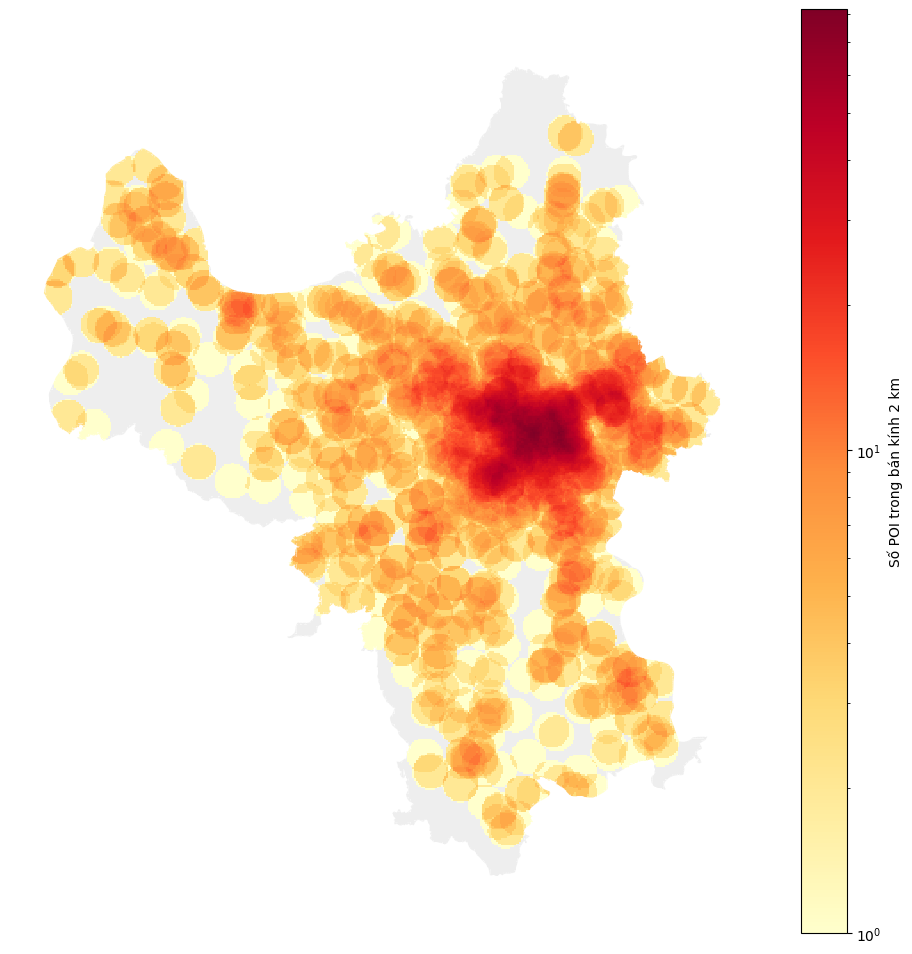

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

column = "school_count_2000m"

fig, ax = plt.subplots(figsize=(12, 12))

features[features[column] == 0].plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="none"
)

positive = features[features[column] > 0]

positive.plot(
    ax=ax,
    column=column,
    cmap="YlOrRd",
    norm=LogNorm(
        vmin=1,
        vmax=positive[column].max()
    ),
    legend=True,
    edgecolor="none",
    legend_kwds={
        "label": "Số POI trong bán kính 2 km"
    }
)

ax.set_axis_off()
plt.show()

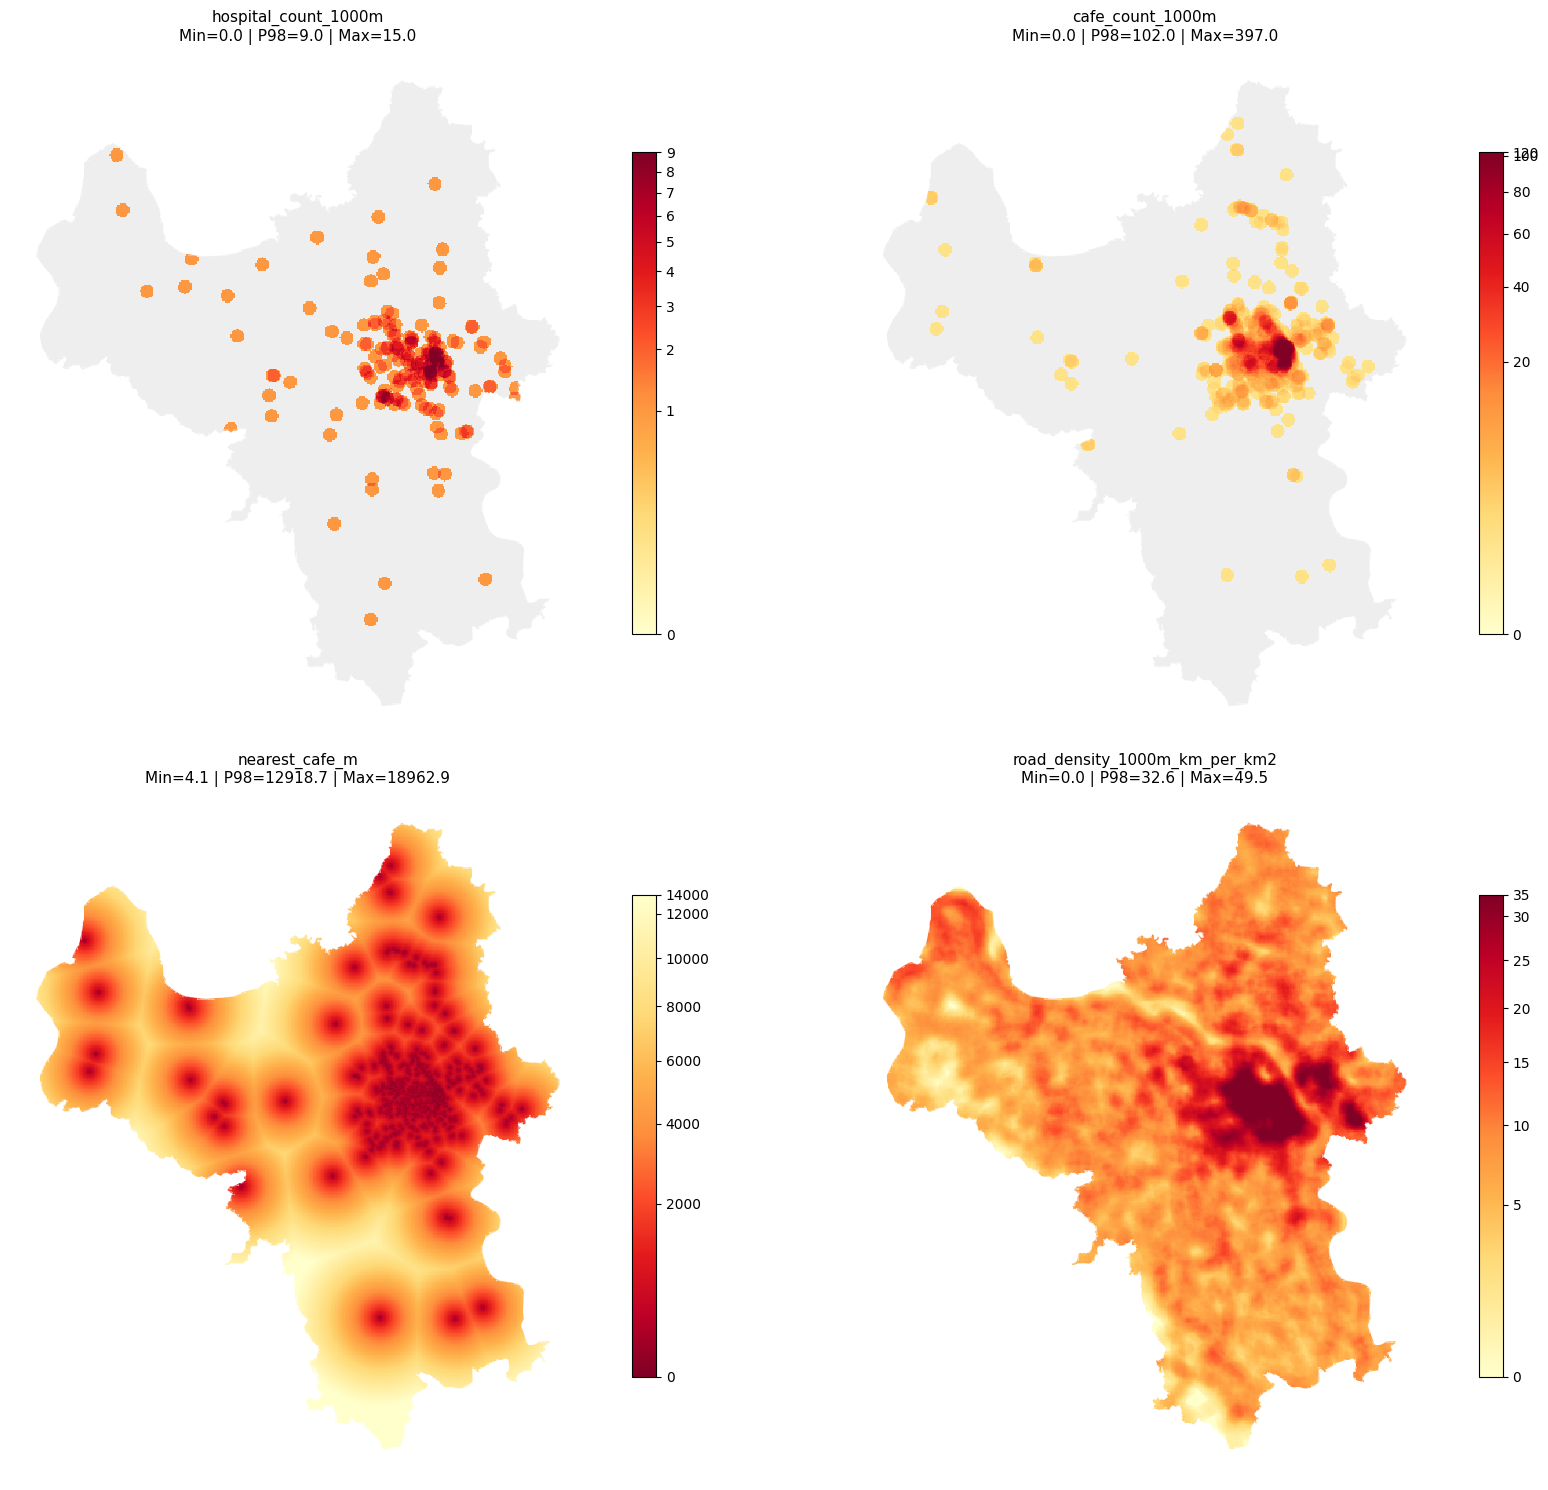

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

requested_columns = [
    "hospital_count_1000m",
    "cafe_count_1000m",
    "nearest_cafe_m",
    "road_density_1000m_km_per_km2",
]

map_columns = [c for c in requested_columns if c in features.columns]

fig, axes = plt.subplots(2, 2, figsize=(18, 15))
axes = axes.ravel()

for ax, col in zip(axes, map_columns):
    values = pd.to_numeric(features[col], errors="coerce")
    valid = values.dropna()

    if valid.empty:
        ax.set_visible(False)
        continue

    is_count = "_count_" in col
    is_distance = col.startswith("nearest_")

    # Với count: không tính zero khi lấy percentile
    positive = values[values > 0]
    reference = positive if is_count else valid

    if reference.empty:
        features.plot(ax=ax, color="#eeeeee", linewidth=0)
        ax.set_title(f"{col} (toàn bộ bằng 0)")
        ax.set_axis_off()
        continue

    # Giới hạn outlier
    vmax = reference.quantile(0.98)

    if vmax <= 0:
        vmax = max(reference.max(), 1e-9)

    # Điều chỉnh độ tương phản
    gamma = 0.35 if is_count else 0.55

    norm = PowerNorm(
        gamma=gamma,
        vmin=0,
        vmax=vmax,
        clip=True,
    )

    # Khoảng cách: gần hơn thì màu đỏ hơn
    cmap = "YlOrRd_r" if is_distance else "YlOrRd"

    if is_count:
        # Vẽ nền xám cho những ô bằng 0 / thiếu dữ liệu
        features.plot(
            ax=ax,
            color="#eeeeee",
            linewidth=0,
        )

        # Chỉ tô màu các ô có POI
        mask = values > 0

        features.loc[mask].plot(
            ax=ax,
            column=col,
            cmap=cmap,
            norm=norm,
            linewidth=0,
            legend=True,
            legend_kwds={"shrink": 0.7},
        )

    else:
        features.assign(_heat=values).plot(
            ax=ax,
            column="_heat",
            cmap=cmap,
            norm=norm,
            linewidth=0,
            legend=True,
            legend_kwds={"shrink": 0.7},
            missing_kwds={"color": "#eeeeee"},
        )

    ax.set_title(
        f"{col}\n"
        f"Min={valid.min():.1f} | "
        f"P98={vmax:.1f} | "
        f"Max={valid.max():.1f}",
        fontsize=11,
    )
    ax.set_axis_off()

for ax in axes[len(map_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

,cell_count
cluster,
0,53860
1,1317
2,26033
3,128
4,3911


,hospital_count_1000m,school_count_1000m,cafe_count_1000m,road_density_1000m_km_per_km2
cluster,,,,
0,0.01,0.26,0.06,6.68
1,4.40,15.77,34.25,35.81
2,0.13,2.20,0.39,12.16
3,7.89,17.48,250.35,35.68
4,1.00,7.09,7.07,25.87


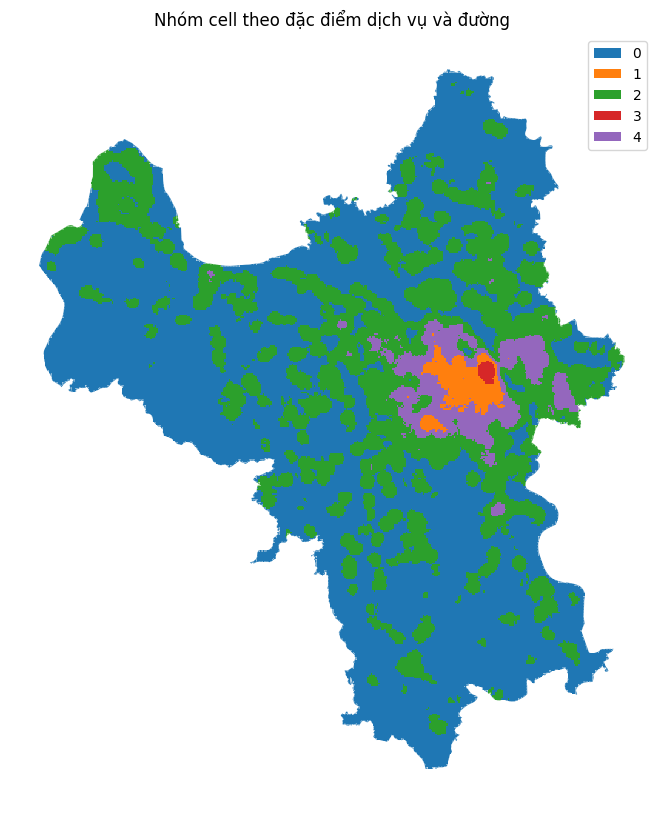

In [6]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

model_columns = [
    "hospital_count_1000m",
    "school_count_1000m",
    "supermarket_count_1000m",
    "cafe_count_1000m",
    "road_density_1000m_km_per_km2",
    "bank_1000m",
]
model_columns = [c for c in model_columns if c in features.columns]

X = features[model_columns].fillna(0)
X_scaled = StandardScaler().fit_transform(X)

model = KMeans(n_clusters=5, random_state=42, n_init=10)
features["cluster"] = model.fit_predict(X_scaled)

cluster_sizes = features["cluster"].value_counts().sort_index()
cluster_profile = features.groupby("cluster")[model_columns].mean().round(2)

display(cluster_sizes.to_frame("cell_count"))
display(cluster_profile)

fig, ax = plt.subplots(figsize=(10, 10))

features.plot(
    ax=ax,
    column="cluster",
    categorical=True,
    legend=True,
    cmap="tab10",
)

ax.set_title("Nhóm cell theo đặc điểm dịch vụ và đường")
ax.set_axis_off()
plt.show()

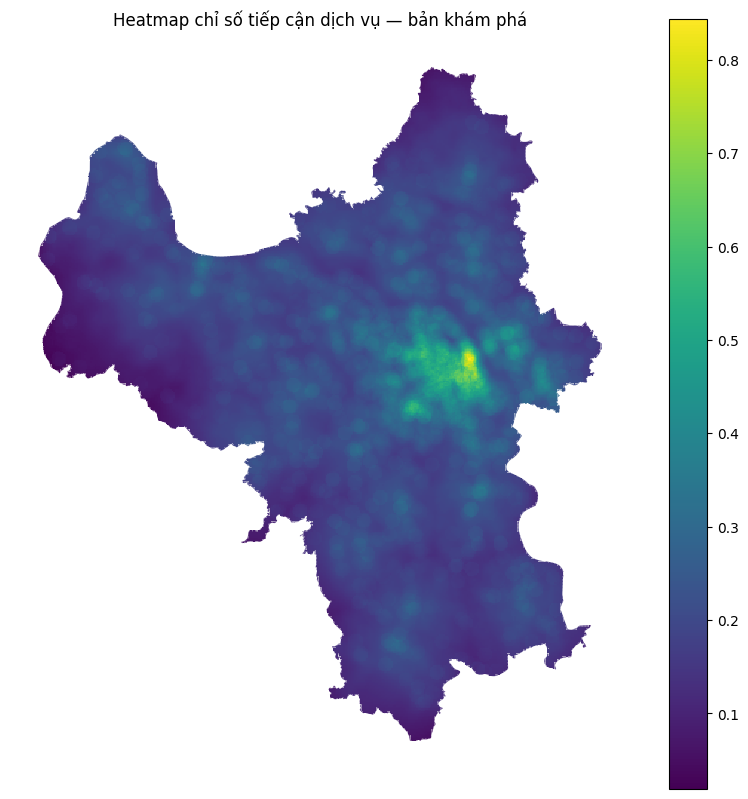

In [5]:
score_columns = [
    "hospital_count_1000m",
    "school_count_1000m",
    "supermarket_count_1000m",
    "nearest_hospital_m",
    "cafe_count_1000m",
    "road_density_1000m_km_per_km2",
]
score_columns = [c for c in score_columns if c in features.columns]

normalized = pd.DataFrame(index=features.index)

for score_column in score_columns:
    values = features[score_column]
    value_range = values.max() - values.min()
    scaled = (values - values.min()) / value_range if value_range else 0.0

    if score_column.startswith("nearest_"):
        scaled = 1 - scaled

    normalized[score_column] = pd.Series(scaled, index=features.index).fillna(0)

features["exploratory_score"] = normalized.mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 10))

features.plot(
    ax=ax,
    column="exploratory_score",
    legend=True,
    cmap="viridis",
)

ax.set_title("Heatmap chỉ số tiếp cận dịch vụ — bản khám phá")
ax.set_axis_off()
plt.show()

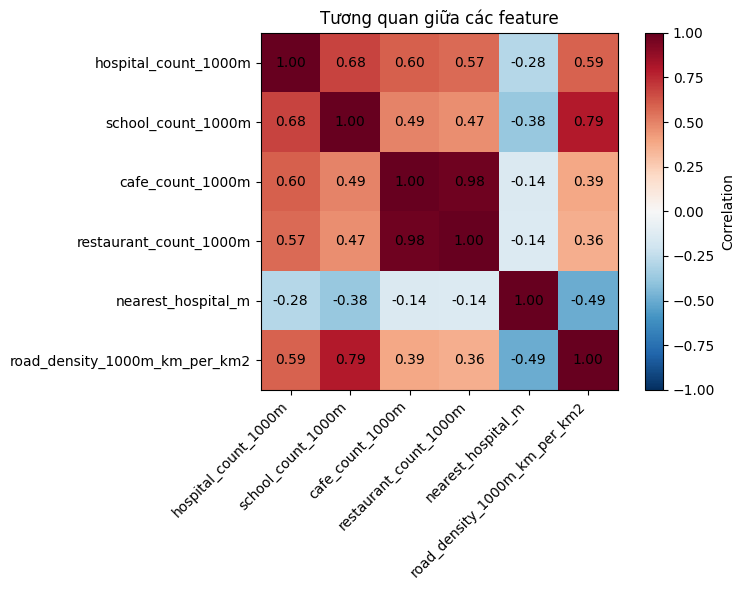

In [21]:
requested_columns = [
    "hospital_count_1000m",
    "school_count_1000m",
    "supermarket_count_1000m",
    "cafe_count_1000m",
    "restaurant_count_1000m",
    "nearest_hospital_m",
    "road_density_1000m_km_per_km2",
]
corr_columns = [c for c in requested_columns if c in features.columns]
corr = features[corr_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_columns)), corr_columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_columns)), corr_columns)

for row in range(len(corr_columns)):
    for col in range(len(corr_columns)):
        ax.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center")

fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Tương quan giữa các feature")
plt.tight_layout()
plt.show()